Problem 1: Suppose the data are `[1, 1.75, 2, 3, 3.25, 4]

1a) Sketch the empirical cumulative distribution function.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

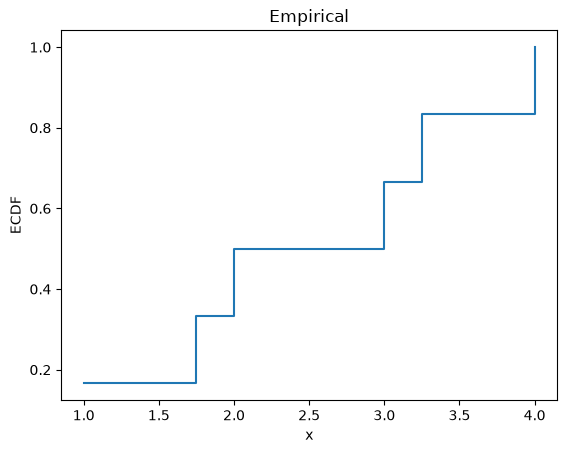

In [2]:
X = np.array([1, 1.75, 2, 3, 3.25, 4])

n = len(X)

x = np.sort(X)
y = np.arange(1, n + 1) / n

plt.step(x, y, where='post')

plt.xlabel('x')
plt.ylabel('ECDF')
plt.title('Empirical')

plt.show()

1b) Sketch the uniform kernel density estimator for a bandwidth of `h = 0.2`

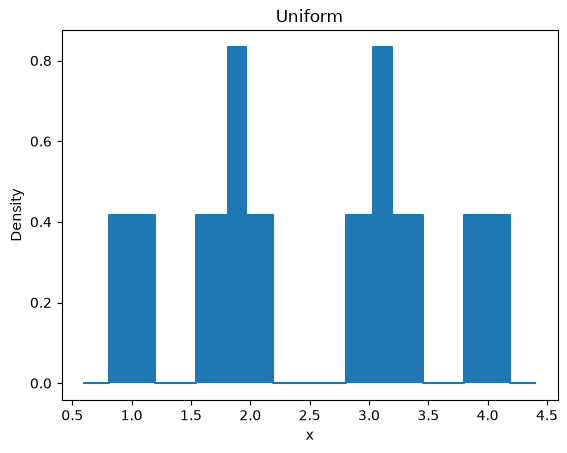

In [3]:
h = 0.2
n = len(X)

x_grid = np.linspace(X.min() - 2*h, X.max() + 2*h, 100)

I = np.abs(x_grid[:, None] - X[None, :]) < h

f_hat = np.sum(I, axis=1) / (2 * n * h)

plt.step(x_grid, f_hat, where='mid')
plt.fill_between(x_grid, f_hat, step='mid')

plt.xlabel('x')
plt.ylabel('Density')
plt.title('Uniform')

plt.show()

1c) Compute the Silverman bandwidth for the uniform kernel using `h = 1.84 * SD * n**(-0.2)`

In [4]:
n = len(X)

h = 1.84 * X.std() * n ** (-0.2)

print(h)

1.2991670409500977


1d) Sketch the uniform kernel density estimator for the Silverman bandwidth.

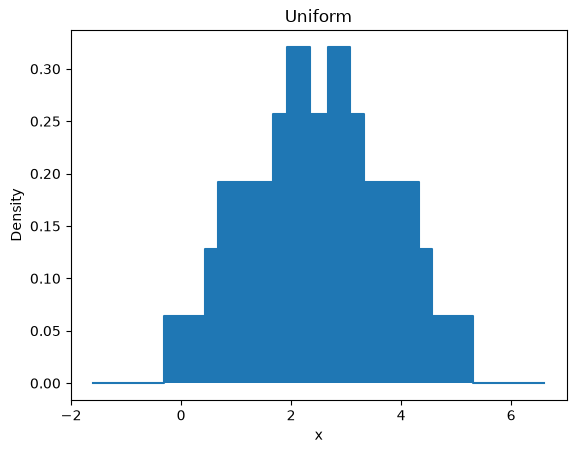

In [5]:
n = len(X)

x_grid = np.linspace(X.min() - 2*h, X.max() + 2*h, 100)

I = np.abs(x_grid[:, None] - X[None, :]) < h

f_hat = np.sum(I, axis=1) / (2 * n * h)

plt.step(x_grid, f_hat, where='mid')
plt.fill_between(x_grid, f_hat, step='mid')

plt.xlabel('x')
plt.ylabel('Density')
plt.title('Uniform')

plt.show()

1e) How are b and d similar or different?

B and D present different bandwidth such as B(h)=0.2 and D(h)=1.299. B has a signficantly smaller bandwidth compared to D. 

Problem 2: Suppose the data `X = [-1, -0.5, 0, 0.5, 1]` were drawn from a standard Normal distribution.

2a) Using the uniform kernel with `h = 0.6`, compute the realized KDE at `x = 0`, `f_hat_h(0)`, directly from these five numbers.

In [6]:
X = np.array([-1, -0.5, 0, 0.5, 1])

n = len(X)
h = 0.6
x = 0

I = np.abs(X - x) < h

f_hat = np.sum(I) / (2 * n * h)

print(f_hat)

0.5


2b) Now compute `E[f_hat_h(0)]` at the same `h = 0.6`

In [7]:
h = 0.6
x = 0

expected_f_hat = (norm.cdf(x + h) - norm.cdf(x - h)) / (2 * h)

print(expected_f_hat)

0.3762448037498774


2c) Calculate the true density at `x=0`, using the Normal distribution.

In [8]:
true_density = norm.pdf(0)

print(true_density)

0.3989422804014327


2d) Are b and c equal? What does this mean about bias? (Keep in mind, truly proving anything about bias would require us to compare `E[f_hat_h]` to the Normal distribution for all x; calculating this at one point is only an indication of what is going on that you can extrapolate from.)

In [9]:
print(expected_f_hat)
print(true_density)

print(expected_f_hat == true_density)

0.3762448037498774
0.3989422804014327
False


2e) Recompute `E[f_hat_h(0)]` from (b) at a much smaller bandwidth, `h = 0.1`. What happens to the gap between `E[f_hat_h(0)]` and `f(0)` as `h` shrinks?

In [10]:
bias = expected_f_hat - true_density

print(bias)

-0.022697476651555304


2f) Is `f_hat_h` a consistent estimator? Explain your reasoning.

f_hate_h is a consistent estimator because when the sample size increases, the bandwidth decreases. 

2g) What are the main considerations in choosing a bandwidth value `h`?

In order to choose a bandwidth value h it has to be to balance between bias and variance. This is because if the value changing too much (variance) but the value bias is decreasing it can cause an unbalance with the bandwidth. 

Question 3: Suppose the data are `X = [5, 7, 7, 8, 10]`, and fix the bandwidth at `h = 1.5` for both kernels below.

3a) Compute the uniform-kernel KDE, `f_hat_h(x)`, at `x = 6.0`, `x = 6.5`, `x = 7.0`, `x = 8.0`, and `x = 8.5`.

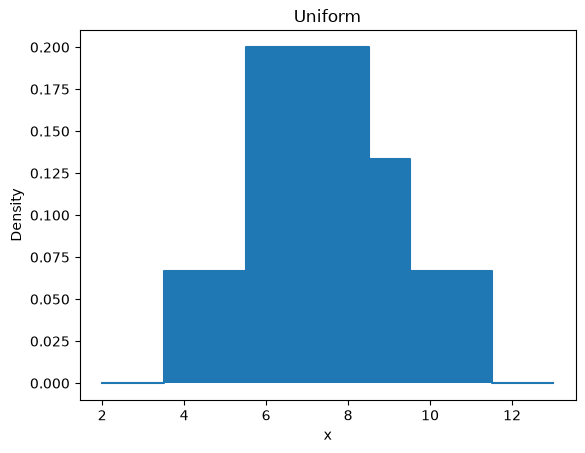

In [11]:
X = np.array([5, 7, 7, 8, 10])

n = len(X)
h = 1.5

x_grid = np.linspace(X.min() - 2*h, X.max() + 2*h, 100)

I = np.abs(x_grid[:, None] - X[None, :]) < h

f_hat = np.sum(I, axis=1) / (2 * n * h)

plt.step(x_grid, f_hat, where='mid')
plt.fill_between(x_grid, f_hat, step='mid')

plt.xlabel('x')
plt.ylabel('Density')
plt.title('Uniform')

plt.show()

3b) Compute the Gaussian-kernel KDE at the same five values of `x`, using the same `h = 1.5`

In [12]:
gauss = lambda z: np.exp(-z**2 / 2) / np.sqrt(2 * np.pi)

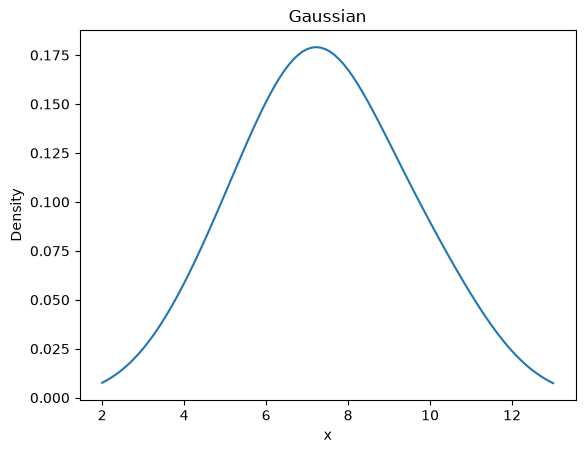

In [13]:
X = np.array([5, 7, 7, 8, 10])

n = len(X)
h = 1.5

x_grid = np.linspace(X.min() - 2*h, X.max() + 2*h, 100)

gauss = lambda z: np.exp(-z**2 / 2) / np.sqrt(2 * np.pi)

K = gauss((x_grid[:, None] - X[None, :]) / h) / h

f_hat = K.mean(axis=1)

plt.plot(x_grid, f_hat)

plt.xlabel('x')
plt.ylabel('Density')
plt.title('Gaussian')

plt.show()

3c) Your part (a) values should jump abruptly between some of these five points, while your part (b) values should change smoothly. Identify where the biggest jump in (a) happens, and explain in terms of the two kernel *shapes* -- not just "one is smoother" -- why that jump exists in the uniform case but not the Gaussian case.

The main difference in shape between the uniform and gaussian graphs is that the uniform present a more block like graph, while the gaussian presents a curve like graph. 
The biggest jump appears to occur right before th 6 mark to after th 6 mark. I believe the jump occurred in the uniform due to the values drastically increased. 

3d) Why might you prefer one kernel over the other in practice?

If you wanted to see where specifically each value lands on that would be the gaussian, while if you're look for more of an estimation between values the uniform graph demonstrates that. 

Question 4: Load `./data/heart_failure_clinical_records_dataset.csv`.

4a) Plot a
- kernel density estimate of `ejection_fraction`.

In [14]:
df = pd.read_csv('./data/heart_failure_clinical_records_dataset.csv')
df

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
294,62.0,0,61,1,38,1,155000.00,1.1,143,1,1,270,0
295,55.0,0,1820,0,38,0,270000.00,1.2,139,0,0,271,0
296,45.0,0,2060,1,60,0,742000.00,0.8,138,0,0,278,0
297,45.0,0,2413,0,38,0,140000.00,1.4,140,1,1,280,0


In [15]:
def kde(X, K=30):
    n = len(X)
    X = np.array(X)

    h_u = 1.84 * X.std() * n ** (-0.2)

    x_grid = np.linspace(X.min() - 2*h_u, X.max() + 2*h_u, K)

    I = np.abs(x_grid[:, None] - X[None, :]) < h_u

    f_hat = np.sum(I, axis=1) / (2 * n * h_u)

    plt.step(x_grid, f_hat, where='mid')
    plt.fill_between(x_grid, f_hat, step='mid')

    plt.xlabel('Ejection Fraction')
    plt.ylabel('Density')
    plt.title('KDE')

    plt.show()

    return x_grid, f_hat

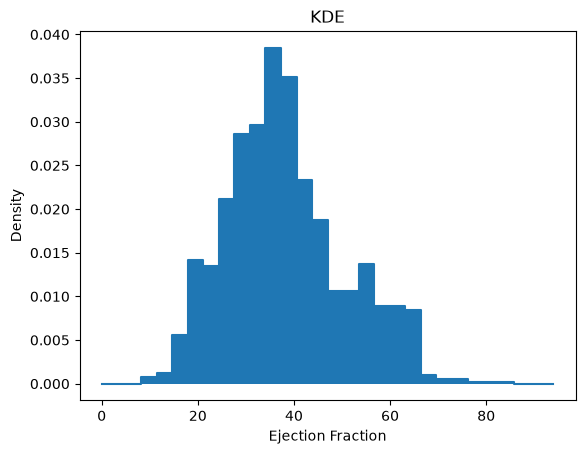

(array([ 0.09571897,  3.33049697,  6.56527498,  9.80005298, 13.03483098,
        16.26960898, 19.50438698, 22.73916499, 25.97394299, 29.20872099,
        32.44349899, 35.67827699, 38.913055  , 42.147833  , 45.382611  ,
        48.617389  , 51.852167  , 55.086945  , 58.32172301, 61.55650101,
        64.79127901, 68.02605701, 71.26083501, 74.49561302, 77.73039102,
        80.96516902, 84.19994702, 87.43472502, 90.66950303, 93.90428103]),
 array([0.        , 0.        , 0.        , 0.00072161, 0.00120268,
        0.00553233, 0.01419163, 0.01347002, 0.02116718, 0.0286238 ,
        0.02958594, 0.03848578, 0.03511827, 0.023332  , 0.01876182,
        0.01058359, 0.01058359, 0.01371056, 0.00889984, 0.00889984,
        0.00841876, 0.00096214, 0.00048107, 0.00048107, 0.00024054,
        0.00024054, 0.00024054, 0.        , 0.        , 0.        ]))

In [16]:
kde(df['ejection_fraction'])

4b) Use Pandas' `df.sample(frac=1.0, replace=True)` to resample the data 15 times with replacement, plotting the kernel density estimtes for each sample.

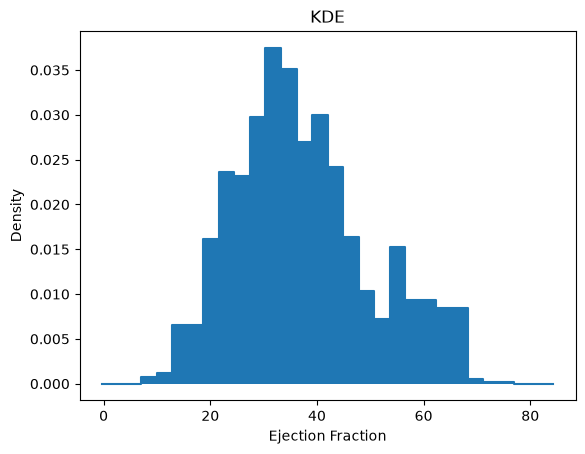

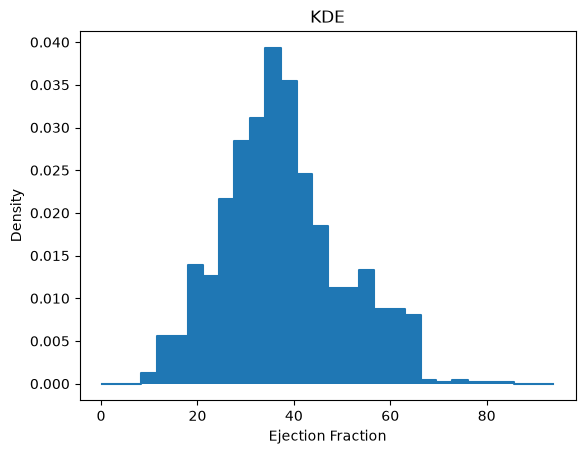

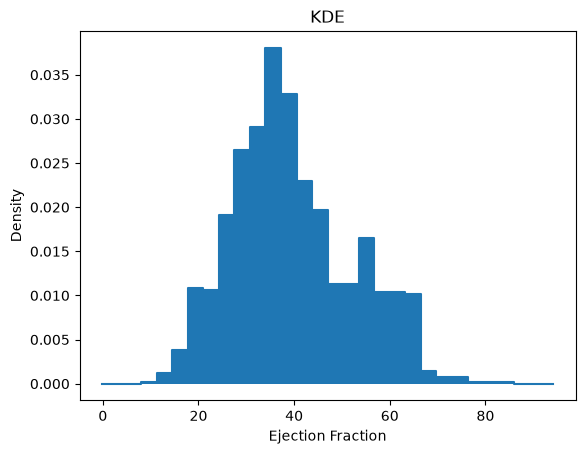

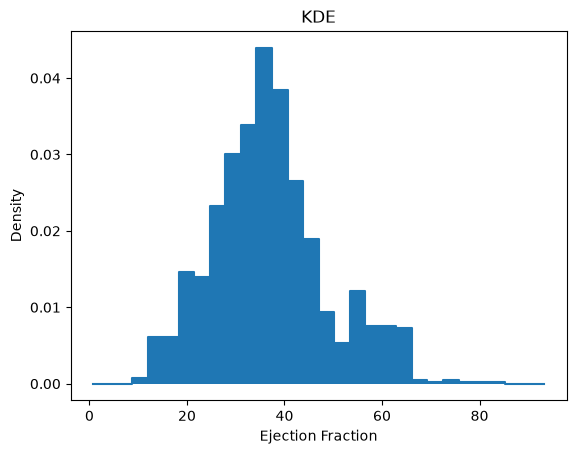

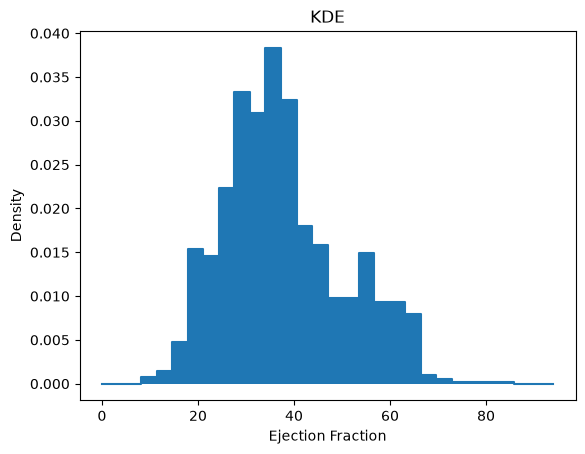

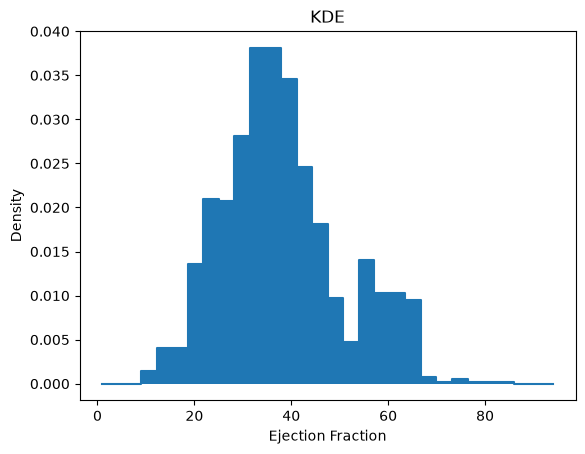

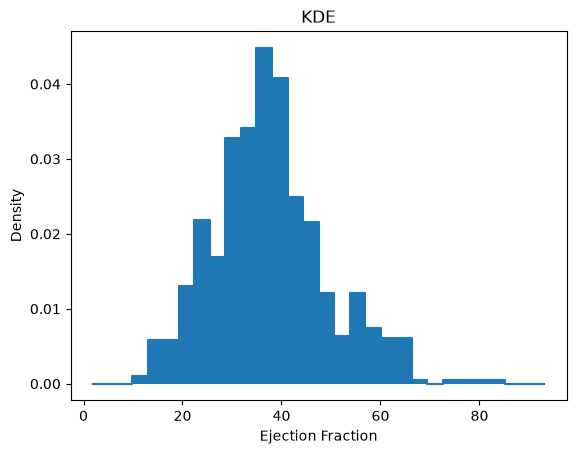

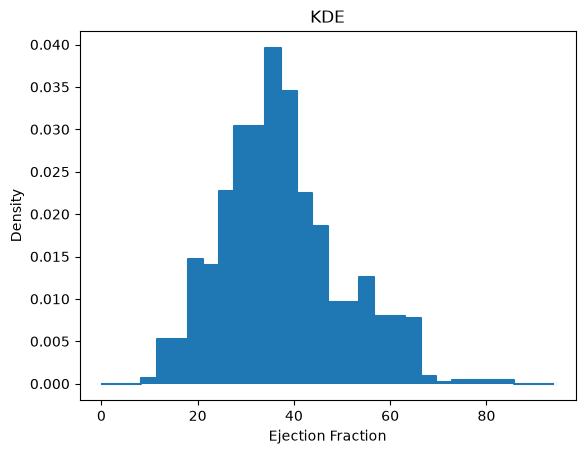

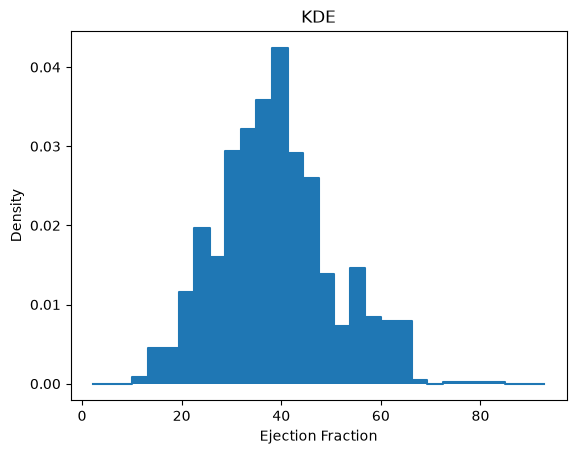

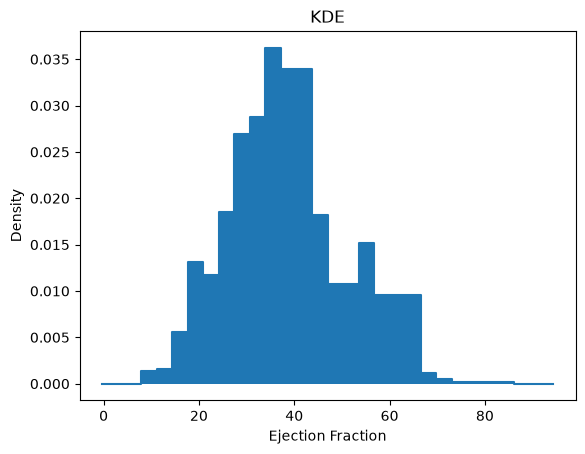

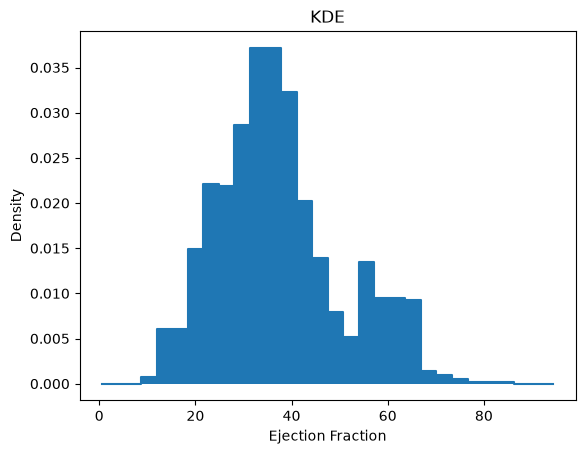

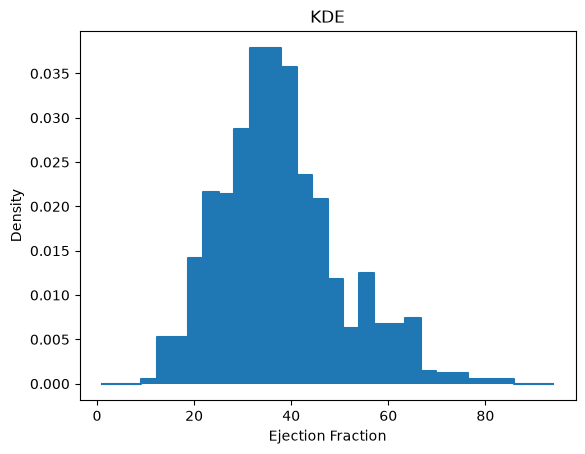

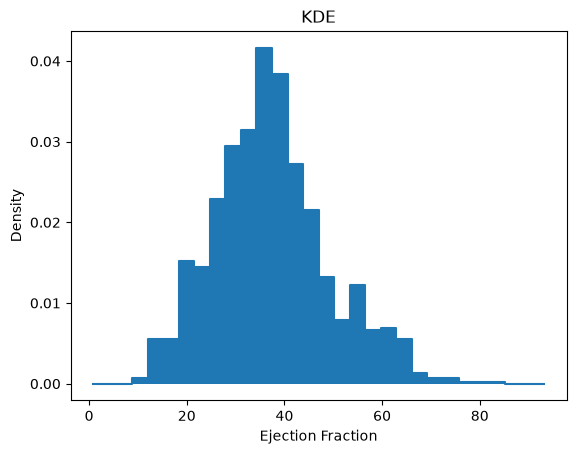

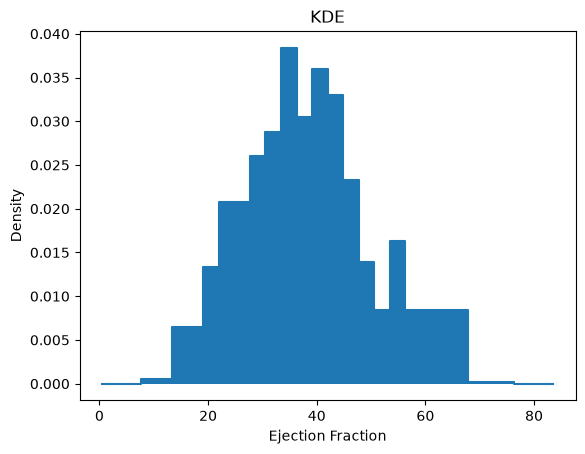

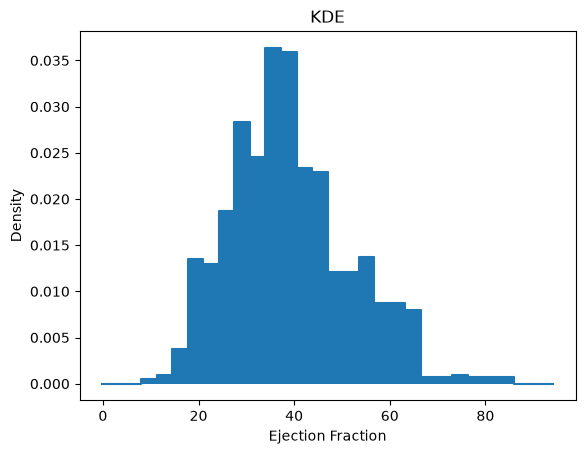

In [17]:
for i in range(15):
    sample = df.sample(frac=1.0, replace=True)

    kde(sample['ejection_fraction'])

4c) For what values of `ejection_fraction` is the original plot reliable? For which values is there noticeable variation in your plots of the resampled data?

It appears that the values between 20 to 60 of `ejection_fraction` are reliable. There is anoticeable variation in the lower and upper ends of the plots.